In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns                   # can understand patterns and relationships before training a model.

In [5]:
#Load Dataset

In [6]:
df = pd.read_csv("shopping.csv")
print(df)

       Administrative  Administrative_Duration  Informational  \
0                   0                      0.0              0   
1                   0                      0.0              0   
2                   0                      0.0              0   
3                   0                      0.0              0   
4                   0                      0.0              0   
...               ...                      ...            ...   
12325               3                    145.0              0   
12326               0                      0.0              0   
12327               0                      0.0              0   
12328               4                     75.0              0   
12329               0                      0.0              0   

       Informational_Duration  ProductRelated  ProductRelated_Duration  \
0                         0.0               1                 0.000000   
1                         0.0               2                64.000000 

In [7]:
df = pd.read_csv("shopping.csv")
print(df.head())        # View first 5 rows


   Administrative  Administrative_Duration  Informational  \
0               0                      0.0              0   
1               0                      0.0              0   
2               0                      0.0              0   
3               0                      0.0              0   
4               0                      0.0              0   

   Informational_Duration  ProductRelated  ProductRelated_Duration  \
0                     0.0               1                 0.000000   
1                     0.0               2                64.000000   
2                     0.0               1                 0.000000   
3                     0.0               2                 2.666667   
4                     0.0              10               627.500000   

   BounceRates  ExitRates  PageValues  SpecialDay Month  OperatingSystems  \
0         0.20       0.20         0.0         0.0   Feb                 1   
1         0.00       0.10         0.0         0.0   Feb   

In [8]:
#Understand the Data

In [9]:

print("Shape:", df.shape)        # Shape (rows, columns)
print(df.columns)                # Column names
print(df.info())                 # Info
print(df.isnull().sum())         # Check missing values


Shape: (12330, 18)
Index(['Administrative', 'Administrative_Duration', 'Informational',
       'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration',
       'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay', 'Month',
       'OperatingSystems', 'Browser', 'Region', 'TrafficType', 'VisitorType',
       'Weekend', 'Revenue'],
      dtype='object')
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12330 entries, 0 to 12329
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Administrative           12330 non-null  int64  
 1   Administrative_Duration  12330 non-null  float64
 2   Informational            12330 non-null  int64  
 3   Informational_Duration   12330 non-null  float64
 4   ProductRelated           12330 non-null  int64  
 5   ProductRelated_Duration  12330 non-null  float64
 6   BounceRates              12330 non-null  float64
 7   ExitRates                12330 n

In [10]:
#Basic Data Cleaning

In [11]:
# Convert TRUE/FALSE to 1/0
df['Revenue'] = df['Revenue'].astype(int)       # 'Revenue' = column name
df['Weekend'] = df['Weekend'].astype(int)

# Convert categorical columns
df = pd.get_dummies(df, drop_first=True)        #  pd.get_dummies() is used to convert text (categorical data) into numbers.

print(df.head())

   Administrative  Administrative_Duration  Informational  \
0               0                      0.0              0   
1               0                      0.0              0   
2               0                      0.0              0   
3               0                      0.0              0   
4               0                      0.0              0   

   Informational_Duration  ProductRelated  ProductRelated_Duration  \
0                     0.0               1                 0.000000   
1                     0.0               2                64.000000   
2                     0.0               1                 0.000000   
3                     0.0               2                 2.666667   
4                     0.0              10               627.500000   

   BounceRates  ExitRates  PageValues  SpecialDay  ...  Month_Feb  Month_Jul  \
0         0.20       0.20         0.0         0.0  ...       True      False   
1         0.00       0.10         0.0         0.0  .

In [12]:
# Exploratory Data Analysis (EDA)

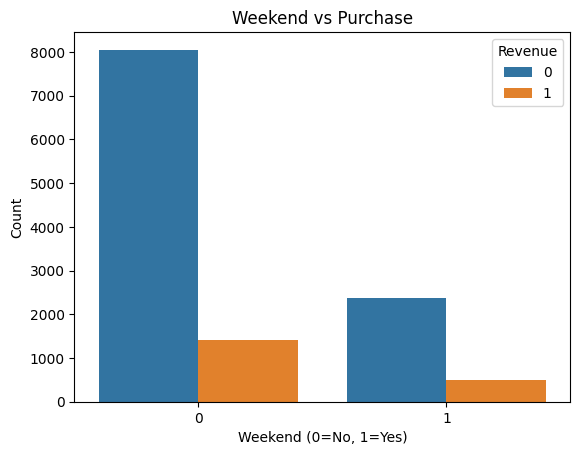

In [13]:
sns.countplot(x='Weekend', hue='Revenue', data=df)     # It creates a count graph (bar chart) using Seaborn.
plt.title("Weekend vs Purchase")
plt.xlabel("Weekend (0=No, 1=Yes)")
plt.ylabel("Count")
plt.show()

In [14]:
# Purchase Distribution

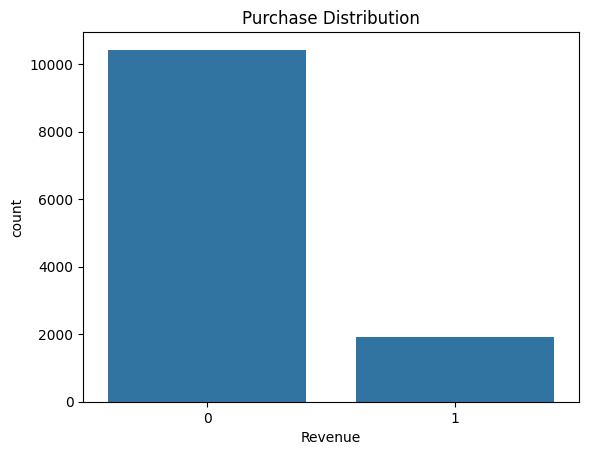

In [15]:
# We use this to visualize how many users purchased vs not purchased.   0-->not a weekend , 1--> weekend

sns.countplot(x='Revenue', data=df)
plt.title("Purchase Distribution")
plt.show()


In [16]:
# Correlation Heatmap

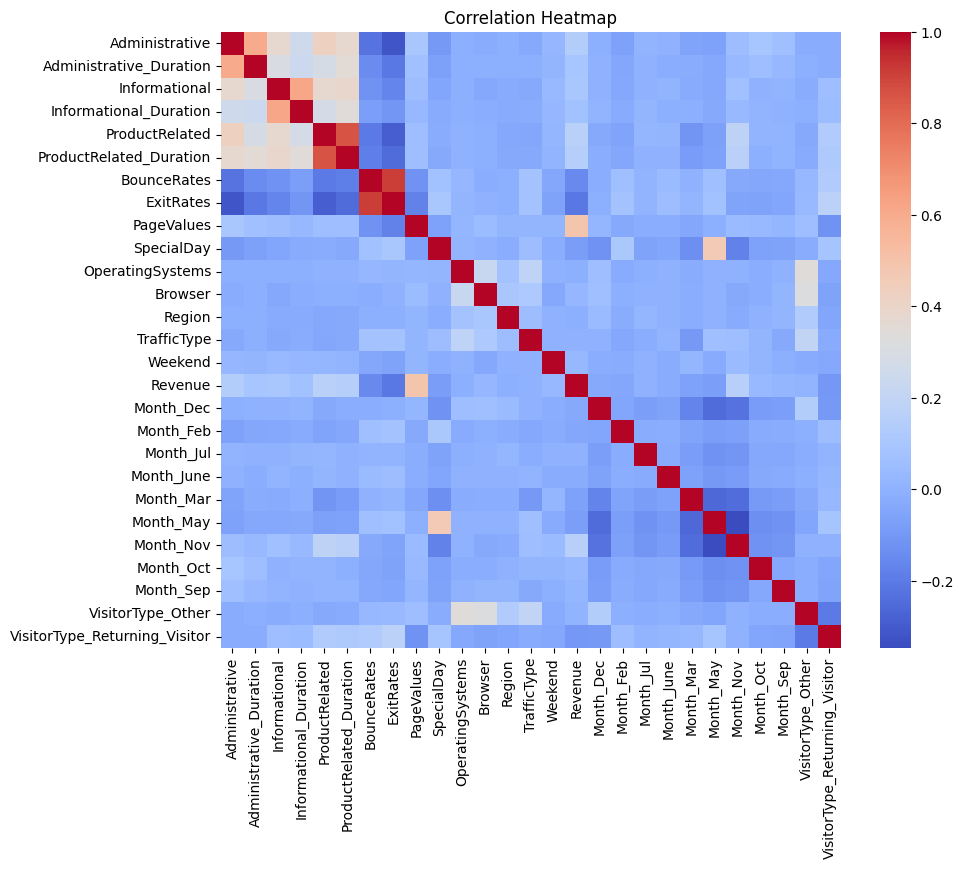

In [17]:
"""
“Which features are strongly related to each other and to the target (Revenue)”
Value ranges from -1 to +1
Value	Meaning
+1	Strong positive relation
0	No relation
-1	Strong negative relation
"""
plt.figure(figsize=(10,8))
sns.heatmap(df.corr(), cmap='coolwarm')             #A heatmap is a graph that shows values using colors.
plt.title("Correlation Heatmap")
plt.show()

In [18]:
# Feature Selection

In [19]:
X = df.drop('Revenue', axis=1)  # input
y = df['Revenue']               # output

In [20]:
# Train-Test Split

In [43]:
"""
random_state = 42?
It means:
“Fix the random splitting so we get the same result every time”
20% of data is used for testing
80% of data is used for training
we can avoid overfitting
"""
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [22]:
# Model Building (Logistic Regression)

In [44]:
# Logistic Regression is a machine learning algorithm used for classification (Yes/No prediction).

from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=1000)   # maximum number of iterations the model uses to converge during training
model.fit(X_train, y_train)

/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


LogisticRegression(max_iter=1000)

In [24]:
# Model Evaluation

In [25]:
"""
What is Model Evaluation?
After training the model, we check how good it is.
1. To Check Accuracy
2. To Avoid Wrong Model
3.To Compare Models
"""

'\nWhat is Model Evaluation?\nAfter training the model, we check how good it is.\n1. To Check Accuracy\n2. To Avoid Wrong Model\n3.To Compare Models\n'

In [27]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
y_pred = model.predict(X_test)
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("Classification Report:\n", classification_report(y_test, y_pred))

Accuracy: 0.8698296836982968
Confusion Matrix:
 [[2007   48]
 [ 273  138]]
Classification Report:
               precision    recall  f1-score   support

           0       0.88      0.98      0.93      2055
           1       0.74      0.34      0.46       411

    accuracy                           0.87      2466
   macro avg       0.81      0.66      0.69      2466
weighted avg       0.86      0.87      0.85      2466



In [45]:
sample = X_test.iloc[0:1].copy()    # It is used to select the first row from the test dataset in table (2D) format.

In [58]:
sample['Weekend'] = 1
sample['PageValues'] = 500
sample['BounceRates'] = 21

In [59]:
prediction = model.predict(sample)

if prediction[0] == 1:
    print("User will Purchase")
else:
    print("User will NOT Purchase")

User will Purchase
